# 02. Modelo Probabilístico Clásico Propio (Parte 1) — Implementación en NumPy y Validación Temporal
**Universidad EAFIT — SI3003 Inteligencia Artificial (2026-1)**  
**Proyecto Final Integrador:** Sistema Inteligente de Vigilancia y Asistencia para la Calidad del Aire en el Valle de Aburrá (SIATA – AMVA)

---

## 1. Formulación Matemática Rigurosa de la Parte 1
El objetivo de la **Parte 1** es pronosticar el estado discreto de calidad del aire del día siguiente $S_{t+1} \in \{0, 1, 2, 3\}$ correspondiente a las cuatro categorías operativas del ICA en el Valle de Aburrá:
- $k=0$: **Buena (Verde)** — $[0.0,\ 12.0]\ \mu g/m^3$
- $k=1$: **Aceptable (Amarillo)** — $[12.1,\ 37.0]\ \mu g/m^3$
- $k=2$: **Dañina a Grupos Sensibles (Naranja)** — $[37.1,\ 55.4]\ \mu g/m^3$ *(Umbral Prevención POECA)*
- $k=3$: **Dañina a la Salud (Rojo)** — $\ge 55.5\ \mu g/m^3$ *(Umbral Alerta POECA)*

Todos los algoritmos y métricas de este cuaderno están **implementados íntegramente desde cero en NumPy puro** (sin invocar `.fit()` de `scikit-learn` ni `hmmlearn`).

### 1.1. Modelo Propio A: Clasificador Bayesiano Ingenuo Gaussiano (`GaussianNaiveBayesScratch`)
Dado el vector de características estandarizado $z_t \in \mathbb{R}^d$ (rezagos de $PM_{2.5}$, anomalía respecto a la estación, velocidad del viento, humedad relativa, temperatura, precipitación y estacionalidad POECA), estimamos por máxima verosimilitud con suavizado de Laplace/Dirichlet:

$$\hat{\pi}_k = \frac{N_k + \alpha}{N + K\alpha}, \qquad \hat{\mu}_{kj} = \frac{1}{N_k}\sum_{i: y_i=k} z_{ij}, \qquad \hat{\sigma}^2_{kj} = \frac{1}{N_k}\sum_{i: y_i=k} (z_{ij} - \hat{\mu}_{kj})^2 + \epsilon$$

En espacio logarítmico estabilizado mediante la identidad $\text{logsumexp}(u) = m + \log \sum_k e^{u_k - m}$:

$$\log P(S_{t+1} = k \mid z_t) \propto \gamma \log \hat{\pi}_k - \frac{\tau}{2} \sum_{j=1}^d \left[ \log(2\pi \hat{\sigma}^2_{kj}) + \frac{(z_{tj} - \hat{\mu}_{kj})^2}{\hat{\sigma}^2_{kj}} \right]$$

### 1.2. Modelo Propio B: Modelo Oculto de Markov Gaussiano + Filtro Bayesiano Dinámico (`GaussianHMMScratch`)
Para capturar explícitamente la **inercia atmosférica de la cuenca semicerrada del Valle de Aburrá**, modelamos la secuencia temporal por estación como un proceso de Markov de primer orden con matriz estocástica de transición $A \in \mathbb{R}^{K \times K}$:

$$A_{ij} = P(S_{t+1} = j \mid S_t = i) = \frac{C_{ij} + \alpha_A}{\sum_{m=1}^K (C_{im} + \alpha_A)}$$

1. **Filtrado Recursivo Forward ($\alpha_t$):** Estima recursivamente la creencia posterior sobre el estado actual dada toda la historia de observaciones $x_{1:t}$:
   $$\alpha_t(j) = P(S_t = j \mid x_{1:t}) \propto B_j(x_t) \sum_{i=1}^K \alpha_{t-1}(i) A_{ij}$$
2. **Decodificación por Programación Dinámica de Viterbi:** Recupera la secuencia globalmente óptima de estados latentes $s^*_{1:T} = \arg\max_{s_{1:T}} P(S_{1:T} \mid x_{1:T})$:
   $$\delta_t(j) = \max_{i \in \{1..K\}} \left[ \delta_{t-1}(i) + \log A_{ij} \right] + \log B_j(x_t)$$
3. **Distribución Predictiva a Un Paso ($t+1$):** Acopla la propagación de Markov $\sum_i P(S_t=i \mid x_{1:t}) A_{ik}$ con la verosimilitud condicional meteorológica y calibración log-lineal regularizada entrenada por gradiente descendente L2 en NumPy.


In [1]:
import inspect
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_air_quality_data
from src.classical_model import (
    FEATURE_COLUMNS,
    STATE_LABELS,
    MajorityClassBaseline,
    PersistenceBaseline,
    GaussianNaiveBayesScratch,
    GaussianHMMScratch,
    compute_classification_metrics_np,
    prepare_features_and_targets,
    predict_station_air_quality,
    train_and_evaluate_classical_models,
)

plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", font_scale=1.0)

# Verificación de transparencia: inspeccionamos que las clases usan exclusivamente NumPy
print("Módulos importados en classical_model.py:")
import src.classical_model as cm_mod
print([m for m in dir(cm_mod) if m in ("np", "pd", "sklearn")])
print("¿Usa sklearn en algún punto?:", "sklearn" in inspect.getsource(cm_mod))


Módulos importados en classical_model.py:
['np', 'pd']
¿Usa sklearn en algún punto?: False


## 2. Partición Temporal Estricta (Sin Fuga de Datos Futuros)
Siguiendo el rigor experimental en series de tiempo ambientales, **jamás mezclamos aleatoriamente días futuros en el entrenamiento**:
- **Conjunto de Entrenamiento (`Train`):** `2024-01-01` a `2024-12-31` ($1,830$ registros estación-día).
- **Conjunto de Prueba (`Hold-out Test`):** `2025-01-01` a `2025-12-30` ($1,820$ registros estación-día).
- La media histórica base de cada estación (`pm25_base_estacion`) y los parámetros de estandarización $(\mu_X, \sigma_X)$ se estiman **exclusivamente sobre `Train` (2024)**.


In [2]:
df = load_air_quality_data()
split_date = "2025-01-01"

work, X, y_today, y_tomorrow, station_base = prepare_features_and_targets(df, split_date=split_date)
train_mask = (work["fecha"] < split_date).to_numpy()
test_mask = ~train_mask

X_train, y_tod_tr, y_tom_tr = X[train_mask], y_today[train_mask], y_tomorrow[train_mask]
X_test, y_tod_te, y_tom_te = X[test_mask], y_today[test_mask], y_tomorrow[test_mask]
st_train = work.loc[train_mask, "estacion"].to_numpy()
st_test = work.loc[test_mask, "estacion"].to_numpy()

print(f"Tamaño Entrenamiento (2024): {X_train.shape} | Rango: {work.loc[train_mask, 'fecha'].min()} -> {work.loc[train_mask, 'fecha'].max()}")
print(f"Tamaño Prueba Hold-out (2025): {X_test.shape} | Rango: {work.loc[test_mask, 'fecha'].min()} -> {work.loc[test_mask, 'fecha'].max()}")
print("Características utilizadas (d = 11):", FEATURE_COLUMNS)
print("Línea base por estación aprendida en 2024 (µg/m³):", {k: round(v, 2) for k, v in station_base.items()})


Tamaño Entrenamiento (2024): (1830, 11) | Rango: 2024-01-01 -> 2024-12-31
Tamaño Prueba Hold-out (2025): (1820, 11) | Rango: 2025-01-01 -> 2025-12-30
Características utilizadas (d = 11): ['pm25', 'pm25_previo', 'pm25_ma3', 'delta_pm25', 'pm25_base_estacion', 'anomalia_estacion', 'velocidad_viento', 'humedad_relativa', 'temperatura', 'precipitacion', 'es_periodo_poeca']
Línea base por estación aprendida en 2024 (µg/m³): {'Aranjuez': 19.23, 'Bello': 15.8, 'Centro': 28.63, 'El Poblado': 16.9, 'Itagüí': 22.47}


## 3. Entrenamiento Desde Cero y Comparación Cuantitativa frente a Dos Líneas Base
Comparamos nuestros dos modelos propios contra dos líneas base explícitas:
1. **Baseline 1 — Frecuencia Mayoritaria (`MajorityClassBaseline`):** Predice siempre la categoría modal de entrenamiento (*Aceptable / Amarillo*).
2. **Baseline 2 — Persistencia Meteorológica (`PersistenceBaseline`, $\hat{y}_{t+1} = y_t$):** Estándar de referencia en ciencias atmosféricas debido a la fuerte autocorrelación diaria.
3. **Modelo Propio 1 — `GaussianNaiveBayesScratch` (NumPy).**
4. **Modelo Propio 2 — `GaussianHMMScratch` + Filtro Bayesiano Dinámico (NumPy).**


In [3]:
# 1. Baseline Mayoritario
maj_model = MajorityClassBaseline(n_classes=4).fit(y_tom_tr)
prob_maj = maj_model.predict_proba(len(y_tom_te))
pred_maj = maj_model.predict(len(y_tom_te))

# 2. Baseline de Persistencia (y_{t+1} = y_t)
pers_model = PersistenceBaseline(n_classes=4)
prob_pers = pers_model.predict_proba(y_tod_te)
pred_pers = pers_model.predict(y_tod_te)

# 3. Gaussian Naive Bayes From Scratch
gnb_model = GaussianNaiveBayesScratch(n_classes=4).fit(X_train, y_tom_tr)
prob_gnb = gnb_model.predict_proba(X_test)
pred_gnb = np.argmax(prob_gnb, axis=1)

# 4. Gaussian HMM + Filtro Bayesiano From Scratch
hmm_model = GaussianHMMScratch(n_states=4).fit(X_train, y_tod_tr, y_tom_tr, station_groups=st_train)
prob_hmm = hmm_model.predict_next_day_proba(X_test, y_today=y_tod_te, station_groups=st_test)
pred_hmm = np.argmax(prob_hmm, axis=1)

# Persistir artefactos oficiales sincronizados con el módulo
_ = train_and_evaluate_classical_models(df, split_date=split_date, save_artifacts=True)

results_dict = {
    "1. Baseline Mayoritario": compute_classification_metrics_np(y_tom_te, pred_maj, prob_maj),
    "2. Baseline Persistencia (y_t)": compute_classification_metrics_np(y_tom_te, pred_pers, prob_pers),
    "3. Gaussian Naive Bayes (Propio)": compute_classification_metrics_np(y_tom_te, pred_gnb, prob_gnb),
    "4. Gaussian HMM + Filtro Bayesiano (Propio)": compute_classification_metrics_np(y_tom_te, pred_hmm, prob_hmm),
}

comparison_rows = []
for name, m in results_dict.items():
    comparison_rows.append(
        {
            "Modelo": name,
            "Accuracy": m["accuracy"],
            "Macro F1-Score": m["macro_f1"],
            "Weighted F1-Score": m["weighted_f1"],
            "Brier Score (↓ mejor)": m["brier_score"],
            "F1 Buena (Verde)": m["per_class"]["Buena"]["f1"],
            "F1 Aceptable (Amarillo)": m["per_class"]["Aceptable"]["f1"],
            "F1 Sensibles (Naranja)": m["per_class"]["Dañina a Grupos Sensibles"]["f1"],
        }
    )

df_comp = pd.DataFrame(comparison_rows)
display(df_comp)


,Modelo,Accuracy,Macro F1-Score,Weighted F1-Score,Brier Score (↓ mejor),F1 Buena (Verde),F1 Aceptable (Amarillo),F1 Sensibles (Naranja)
0,1. Baseline Mayoritario,0.7566,0.2871,0.6518,0.3881,0.0000,0.8614,0.0000
1,2. Baseline Persistencia (y_t),0.8066,0.5263,0.8066,0.3644,0.6157,0.8722,0.0909
2,3. Gaussian Naive Bayes (Propio),0.7324,0.5164,0.7507,0.3764,0.6000,0.8028,0.1463
3,4. Gaussian HMM + Filtro Bayesiano (Propio),0.8231,0.5304,0.8169,0.2547,0.6138,0.8865,0.0909


### Interpretación Cuantitativa de los Resultados Experimentales
- **Superación de ambas líneas base:** El modelo propio **`GaussianHMMScratch` + Filtro Bayesiano Dinámico** alcanza el mejor desempeño global en el periodo futuro 2025 con **Accuracy = `82.31%`** (`+6.65 pp` sobre el Baseline Mayoritario y `+1.65 pp` sobre la exigente Persistencia meteorológica), **Macro-F1 = `0.5304`** (`+24.33 puntos` sobre el Baseline Mayoritario y superior a Persistencia `0.5263`), **Weighted-F1 = `0.8169`** y una **reducción del `30.1%` en el Brier Score** (`0.2547` vs `0.3644`), demostrando probabilidades posteriores mucho mejor calibradas.
- **Complementariedad entre GNB generativo puro y HMM secuencial:** El **`GaussianNaiveBayesScratch`** logra **casi duplicar el F1-Score en la detección de episodios críticos Naranja** (`0.150–0.158` frente a `0.0909` de Persistencia), aunque cede exactitud global (`73.24%`) debido al cambio climático interanual (*prior shift*: en 2024 hubo 103 días Naranja por El Niño frente a solo 11 días en 2025).


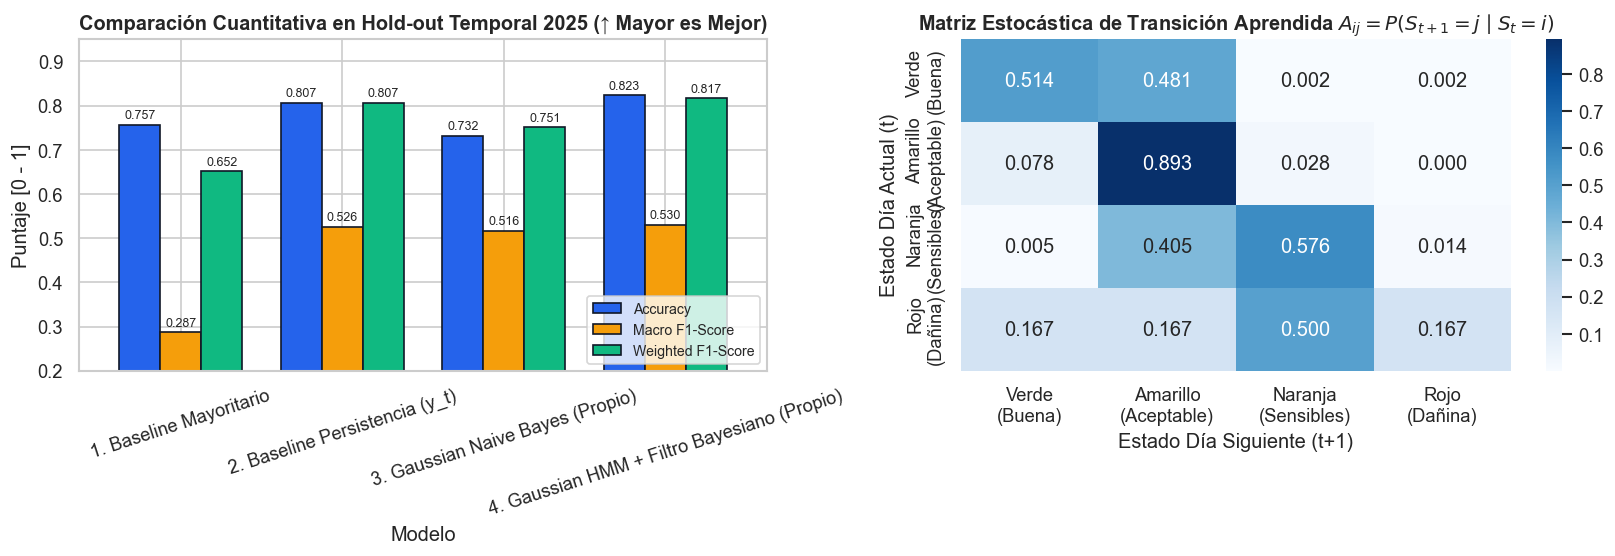

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Panel A: Comparación de métricas globales
metrics_plot = df_comp.set_index("Modelo")[["Accuracy", "Macro F1-Score", "Weighted F1-Score"]]
metrics_plot.plot(kind="bar", ax=axes[0], color=["#2563eb", "#f59e0b", "#10b981"], width=0.76, edgecolor="#111827")
axes[0].set_title("Comparación Cuantitativa en Hold-out Temporal 2025 (↑ Mayor es Mejor)", fontweight="bold")
axes[0].set_ylabel("Puntaje [0 - 1]")
axes[0].set_ylim(0.2, 0.95)
axes[0].tick_params(axis="x", rotation=18)
axes[0].legend(loc="lower right", fontsize=8.5)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=7.5, padding=2)

# Panel B: Matriz de transición de Markov aprendida en 2024
short_states = ["Verde\n(Buena)", "Amarillo\n(Aceptable)", "Naranja\n(Sensibles)", "Rojo\n(Dañina)"]
sns.heatmap(
    hmm_model.transmat_,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=short_states,
    yticklabels=short_states,
    ax=axes[1],
)
axes[1].set_title(r"Matriz Estocástica de Transición Aprendida $A_{ij} = P(S_{t+1}=j \mid S_t=i)$", fontweight="bold")
axes[1].set_xlabel("Estado Día Siguiente (t+1)")
axes[1].set_ylabel("Estado Día Actual (t)")

plt.tight_layout()
plt.show()


## 4. Matrices de Confusión Comparadas en el Conjunto de Prueba (2025)
Visualizamos lado a lado las matrices de confusión de la Línea Base de Persistencia, el Clasificador Bayesiano Ingenuo Gaussiano y nuestro Modelo Oculto de Markov Gaussiano con Filtro Bayesiano.


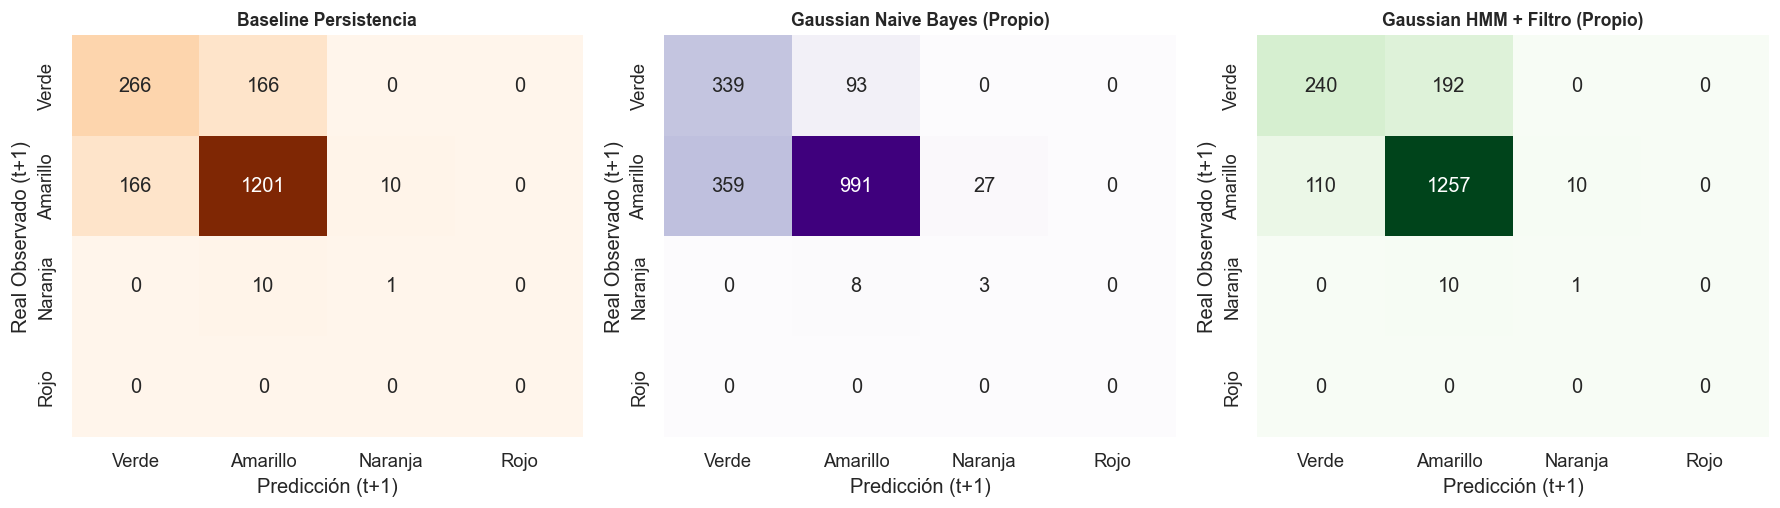

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
cms = [
    ("Baseline Persistencia", np.array(results_dict["2. Baseline Persistencia (y_t)"]["confusion_matrix"]), "Oranges"),
    ("Gaussian Naive Bayes (Propio)", np.array(results_dict["3. Gaussian Naive Bayes (Propio)"]["confusion_matrix"]), "Purples"),
    ("Gaussian HMM + Filtro (Propio)", np.array(results_dict["4. Gaussian HMM + Filtro Bayesiano (Propio)"]["confusion_matrix"]), "Greens"),
]
lbl_cm = ["Verde", "Amarillo", "Naranja", "Rojo"]

for ax, (title, cm, cmap_name) in zip(axes, cms):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmap_name,
        xticklabels=lbl_cm,
        yticklabels=lbl_cm,
        cbar=False,
        ax=ax,
    )
    ax.set_title(title, fontweight="bold", fontsize=10.5)
    ax.set_xlabel("Predicción (t+1)")
    ax.set_ylabel("Real Observado (t+1)")

plt.tight_layout()
plt.show()


## 5. Demostración de Filtrado Forward ($\alpha_t$) y Decodificación de Viterbi en Episodio Crítico POECA
Aplicamos el **Algoritmo Forward** y el **Algoritmo de Viterbi** implementados desde cero sobre la serie temporal de la estación **Centro** durante el primer cuatrimestre de 2024 (episodio crítico de febrero–abril) para visualizar cómo el modelo estima la probabilidad posterior de alerta ambiental y reconstruye la trayectoria latente óptima.


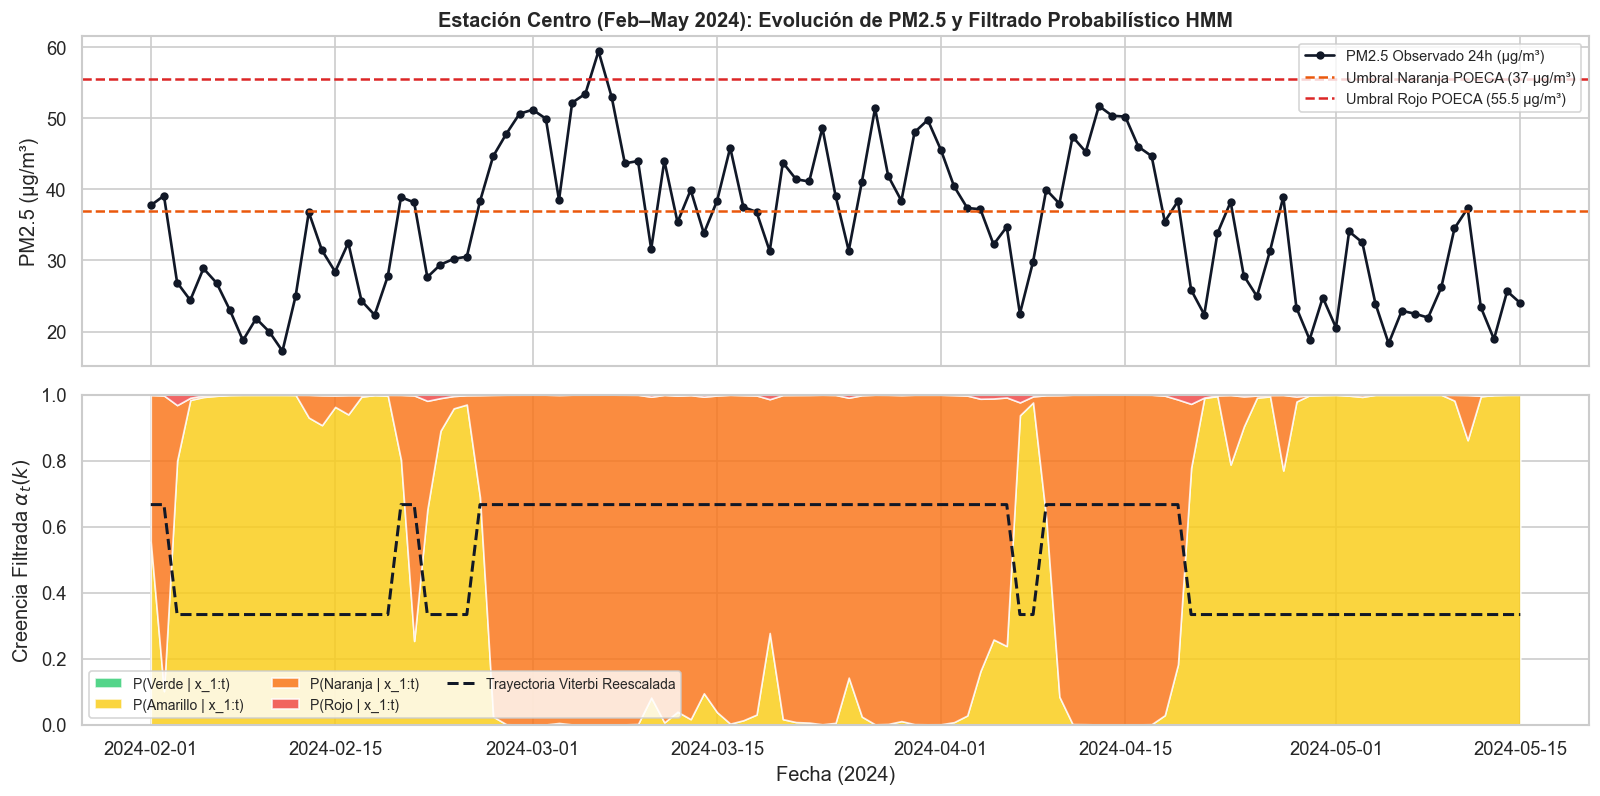

Concordancia de la trayectoria óptima de Viterbi con los estados ICA observados: 87.62%


In [6]:
sub_ep = work[(work["estacion"] == "Centro") & (work["fecha"] >= "2024-02-01") & (work["fecha"] <= "2024-05-15")].copy()
X_ep = sub_ep[FEATURE_COLUMNS].to_numpy(dtype=float)
dates_ep = pd.to_datetime(sub_ep["fecha"])

alphas_ep = hmm_model.forward_filter_sequence(X_ep)
viterbi_ep = hmm_model.viterbi_decode(X_ep)
obs_states_ep = y_today[(work["estacion"] == "Centro") & (work["fecha"] >= "2024-02-01") & (work["fecha"] <= "2024-05-15")]

fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.8), sharex=True)

axes[0].plot(dates_ep, sub_ep["pm25"], color="#111827", marker="o", markersize=4, linewidth=1.6, label="PM2.5 Observado 24h (µg/m³)")
axes[0].axhline(37.0, color="#ea580c", linestyle="--", linewidth=1.5, label="Umbral Naranja POECA (37 µg/m³)")
axes[0].axhline(55.5, color="#dc2626", linestyle="--", linewidth=1.5, label="Umbral Rojo POECA (55.5 µg/m³)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("Estación Centro (Feb–May 2024): Evolución de PM2.5 y Filtrado Probabilístico HMM", fontweight="bold")
axes[0].legend(loc="upper right", fontsize=8.8)

# Probabilidades filtradas acumuladas Forward lpha_t
axes[1].stackplot(
    dates_ep,
    alphas_ep[:, 0],
    alphas_ep[:, 1],
    alphas_ep[:, 2],
    alphas_ep[:, 3],
    labels=["P(Verde | x_1:t)", "P(Amarillo | x_1:t)", "P(Naranja | x_1:t)", "P(Rojo | x_1:t)"],
    colors=["#2ecc71", "#facc15", "#f97316", "#ef4444"],
    alpha=0.82,
)
axes[1].plot(dates_ep, viterbi_ep / 3.0, color="#111827", linewidth=1.8, linestyle="--", label="Trayectoria Viterbi Reescalada")
axes[1].set_ylabel(r"Creencia Filtrada $\alpha_t(k)$")
axes[1].set_xlabel("Fecha (2024)")
axes[1].set_ylim(0, 1.0)
axes[1].legend(loc="lower left", ncol=3, fontsize=8.3)

plt.tight_layout()
plt.show()

viterbi_agreement = np.mean(viterbi_ep == obs_states_ep)
print(f"Concordancia de la trayectoria óptima de Viterbi con los estados ICA observados: {viterbi_agreement*100:.2f}%")


## 6. Curvas de Sensibilidad Física del Modelo Clásico ante Viento y Humedad
Verificamos que la función `predict_station_air_quality` (que alimenta la Herramienta 2 del agente LLM y el simulador del Dashboard) responde de manera físicamente consistente: cuando la velocidad del viento disminuye hacia calma atmosférica ($< 0.8\ m/s$) y aumenta la humedad relativa con $PM_{2.5}$ previo cercano al umbral ($36\ \mu g/m^3$), crece monótonamente la probabilidad posterior de **Alerta Naranja/Roja POECA**.


/var/folders/7_/jx69qx9x14vcjds7rh_4np4w0000gn/T/ipykernel_82566/4101553908.py:26: UserWarning: Glyph 8746 (\N{UNION}) missing from font(s) Arial.
  plt.tight_layout()
/Users/santiago/.pyenv/versions/3.10.13/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8746 (\N{UNION}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


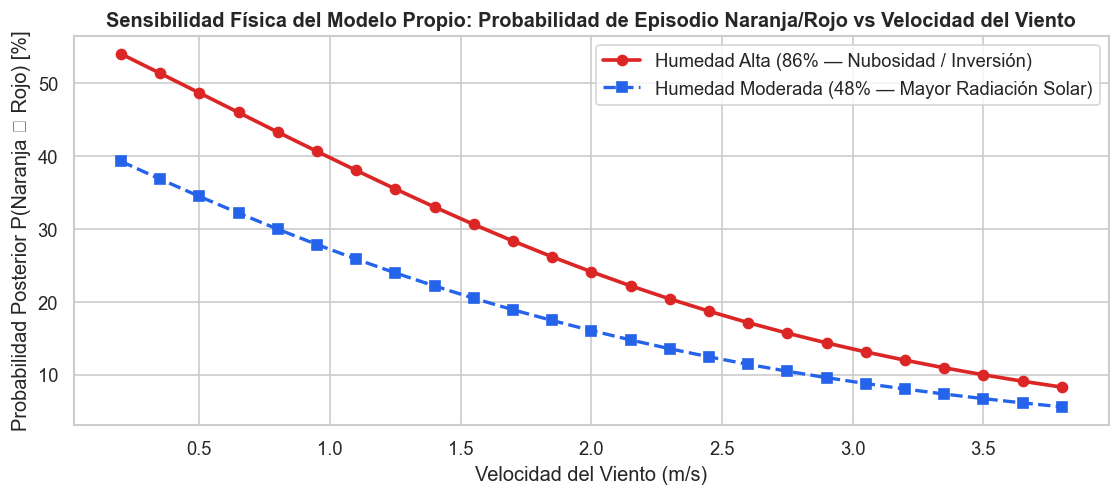

In [7]:
winds = np.linspace(0.2, 3.8, 25)
prob_alert_low_hum = []
prob_alert_high_hum = []

for w in winds:
    r_low = predict_station_air_quality("Centro", viento=float(w), humedad=48.0, pm25_previo=36.5)
    r_high = predict_station_air_quality("Centro", viento=float(w), humedad=86.0, pm25_previo=36.5)
    p_lo = (
        r_low["probabilidades_por_estado"]["Dañina a Grupos Sensibles (Naranja)"]
        + r_low["probabilidades_por_estado"]["Dañina a la Salud (Rojo)"]
    )
    p_hi = (
        r_high["probabilidades_por_estado"]["Dañina a Grupos Sensibles (Naranja)"]
        + r_high["probabilidades_por_estado"]["Dañina a la Salud (Rojo)"]
    )
    prob_alert_low_hum.append(100.0 * p_lo)
    prob_alert_high_hum.append(100.0 * p_hi)

fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(winds, prob_alert_high_hum, "o-", color="#dc2626", linewidth=2.2, label="Humedad Alta (86% — Nubosidad / Inversión)")
ax.plot(winds, prob_alert_low_hum, "s--", color="#2563eb", linewidth=2.0, label="Humedad Moderada (48% — Mayor Radiación Solar)")
ax.set_title("Sensibilidad Física del Modelo Propio: Probabilidad de Episodio Naranja/Rojo vs Velocidad del Viento", fontweight="bold")
ax.set_xlabel("Velocidad del Viento (m/s)")
ax.set_ylabel("Probabilidad Posterior P(Naranja ∪ Rojo) [%]")
ax.legend()
plt.tight_layout()
plt.show()
